In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import torch

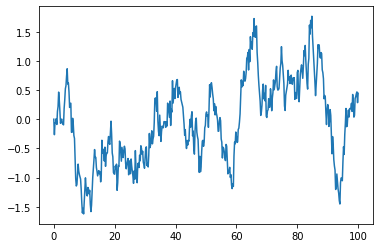

In [26]:
import matplotlib.pyplot as plt
from torch.distributions.normal import Normal

dt = 0.2
period = 100

t0 = 0
t = t0

d0 = 0
current_pos = d0
positions = [d0]
times = [t0]

while t < period:
	sample = Normal(0, dt).sample()
	t += dt
	positions.append(current_pos + sample)
	current_pos += sample
	times.append(t)
plt.plot(times, positions)
plt.show()


/var/folders/00/hcqyg8v94bg2t4q1tl5bk3040000gn/T/ipykernel_28995/424636468.py:44: MatplotlibDeprecationWarning: Calling gca() with keyword arguments was deprecated in Matplotlib 3.4. Starting two minor releases later, gca() will take no keyword arguments. The gca() function should only be used to get the current axes, or if no axes exist, create new axes with default keyword arguments. To create a new axes with non-default arguments, use plt.axes() or plt.subplot().
  ax = fig.gca(projection='3d')
/var/folders/00/hcqyg8v94bg2t4q1tl5bk3040000gn/T/ipykernel_28995/424636468.py:60: DeprecationWarning: Use of `minimize` with `x0.ndim != 1` is deprecated. Currently, singleton dimensions will be removed from `x0`, but an error will be raised in SciPy 1.11.0.
  res = minimize(levy, x0.numpy(), bounds=2*[bounds]);


tensor([0.0042]) [0.94219112 0.90873241]


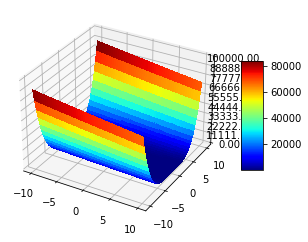

In [28]:
import torch
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 unused import

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import LinearLocator, FormatStrFormatter
import numpy as np
import sys
import math
from scipy.optimize import minimize

def levy(x):
    if not isinstance(x, torch.Tensor): x = torch.tensor(x).float()	
    if len(x.shape) < 2: x = x.unsqueeze(0)
    assert x.shape[1] == 2, 'Input should be of dimension 2'

    w = lambda x: 1. + (x - 1.)/4. 
    result = torch.sin(math.pi * w(x[:,0])) ** 2
    result += torch.sum(((w(x[:,:-1])-1)**2) * (1. + 10*torch.sin(math.pi * w(x[:,:-1]) + 1.) ** 2), dim=1)
    result += ((w(x[:,-1])-1)**2) * (1. + torch.sin(2. * math.pi * w(x[:,-1])) ** 2)

    return result

def dixon_price(x):
    if not isinstance(x, torch.Tensor): x = torch.tensor(x).float()    
    if len(x.shape) < 2: x = x.unsqueeze(0)
    assert x.shape[1] == 2, 'Input should be of dimension 2'

    result = (x[:,0] - 1.) ** 2
    result += 2 * ((2 * (x[:,1] ** 2) - x[:,0]) ** 2)
    return result

def create_hypercube_grid(bounds, num_points, n_dims):
    axpoints = torch.linspace(bounds[0], bounds[1], num_points)
    x = torch.zeros(num_points ** n_dims, n_dims)
    #print(axpoints.unsqueeze(1).repeat(num_points ** (n_dims - 0 - 1), num_points ** (0 + 1)).view(-1))
    for i in range(n_dims):
        x[:,i].copy_(axpoints.unsqueeze(1).repeat(num_points ** (n_dims - 1 - i), num_points ** i).view(-1))
    return torch.flip(x, dims=(1,))

f = dixon_price

fig = plt.figure()
ax = fig.gca(projection='3d')
bounds = (-10.,10.)
# Make data.
X = torch.linspace(-10, 10, 200).unsqueeze(1).repeat(1,200)
Y = torch.linspace(-10, 10, 200).repeat(200,1)

grid = create_hypercube_grid((-10, 10), 200, 2)

Z = f(grid).reshape(200,200)

num_repeats = 10000
min_y = float("inf")
min_x = float("inf")

init_guesses = torch.distributions.uniform.Uniform(torch.tensor([bounds[0]]), torch.tensor([bounds[1]])).sample(torch.Size([num_repeats,2]))
for x0 in init_guesses:
    res = minimize(levy, x0.numpy(), bounds=2*[bounds])
    y = levy(res.x)
    if y < min_y:
        min_y = y
        min_x = res.x

print(min_y, min_x)

# Plot the surface.
surf = ax.plot_surface(X.numpy(), Y.numpy(), Z.numpy(), cmap='jet',
                       linewidth=0, antialiased=False)

# Customize the z axis.
ax.set_zlim(0, 100000)
ax.zaxis.set_major_locator(LinearLocator(10))
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'))

# Add a color bar which maps values to colors.
fig.colorbar(surf, shrink=0.5, aspect=5)

plt.show()

In [36]:
# Binary Classification using Gaussian Processes in GPyTorch
# Dataset is a simulated 2D sinusoid 
# Classes are learned by active learning. Points in 2D space are sampled
# by finding point of the maximum variance of the GP classifier.
# Uses L-BFGS to find maximum points in 2D space

from gpytorch.mlls.variational_elbo import VariationalELBO
import math
import torch
import torch.distributions as dist
import gpytorch
from matplotlib import pyplot as plt
import os
from scipy.optimize import minimize

import pandas as pd
import numpy as np
import seaborn as sns
import sys
import time

from gpytorch.models import AbstractVariationalGP
from gpytorch.variational import CholeskyVariationalDistribution
from gpytorch.variational import VariationalStrategy

#torch.manual_seed(2)

class GPClassificationModel(AbstractVariationalGP):
    def __init__(self, train_x, lengthscale=None):
        variational_distribution = CholeskyVariationalDistribution(train_x.size(0))
        variational_strategy = VariationalStrategy(self, train_x, variational_distribution)
        super(GPClassificationModel, self).__init__(variational_strategy)
        self.mean_module = gpytorch.means.ConstantMean()
        if lengthscale is not None:
        	self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel(lengthscale=lengthscale))
        else:
        	self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel())

    def set_data(self, new_X):
        self.__init__(new_X)

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        latent_pred = gpytorch.distributions.MultivariateNormal(mean_x, covar_x)
        return latent_pred


class VSGPClassificationModel(AbstractVariationalGP):
    def __init__(self, train_x, lengthscale=None):
        variational_distribution = CholeskyVariationalDistribution(train_x.size(0))
        variational_strategy = VariationalStrategy(self, train_x, variational_distribution, learn_inducing_locations=True)
        super(VSGPClassificationModel, self).__init__(variational_strategy)
        self.mean_module = gpytorch.means.ConstantMean()
        if lengthscale is not None:
            self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel(lengthscale=lengthscale))
        else:
            self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel())

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        latent_pred = gpytorch.distributions.MultivariateNormal(mean_x, covar_x)
        return latent_pred


class GPClassifier:
    def __init__(self, sparse=False, n_dims=1):
        # Initialize model and likelihood
        
        self.likelihood = gpytorch.likelihoods.BernoulliLikelihood()
        self.likelihood.train()
        self.sparse = sparse
        self.n_dims = n_dims
        self.X = None
        self.y = None

        self.training_time = 0.0

    def fit(self, X, y, lengthscale=None):
        
        if self.sparse:
            perm = torch.randperm(X.size(0))
            idx = perm[:50]
            self.inducing_points = X[idx]
            self.inducing_points.sort()
            class_model = VSGPClassificationModel
        else:
            self.inducing_points = X
            class_model = GPClassificationModel

        self.X = X
        self.y = y

        self.model = class_model(self.inducing_points, lengthscale)
        # Use the adam optimizer
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=0.1)

        # "Loss" for GPs - the marginal log likelihood
        # num_data refers to the amount of training data
        self.mll = VariationalELBO(self.likelihood, self.model, self.y.numel())

        self.train()

    def train(self, num_steps=50):

        start = time.time()
        for i in range(num_steps):
            # Zero backpropped gradients from previous iteration
            self.optimizer.zero_grad()
            # Get predictive output
            output = self.model(self.X)
            # Calc loss and backprop gradients
            loss = -self.mll(output, self.y)
            loss.backward()
            #print('Iter %d/%d - Loss: %.3f' % (i + 1, num_steps, loss.item()))
            self.optimizer.step()

        end = time.time()
        self.training_time += end - start

    def update_post(self, X, y):
        if not isinstance(X, torch.Tensor):
            X = torch.tensor(X).float()

        if not isinstance(y, torch.Tensor):
            y = torch.tensor(y).float()

        if self.X is not None:
            #print(X.shape, self.X.shape)
            assert X.shape[1] == self.X.shape[1], 'Input shape does not match'

        else:
            self.fit(X, y)
            return 0

        lengthscale = self.model.covar_module.base_kernel.lengthscale.item()
        self.fit(torch.cat((self.X, X), dim=0), torch.cat((self.y, y), dim=0), lengthscale=lengthscale)

    def forward(self, X):
        with torch.no_grad():
            pred_f = self.model(X)

            return pred_f

    def predict(self, X, y=None, acc=True):

        if acc:
            assert y is not None, 'target labels required to calculate accuracy'

        self.model.eval()
        self.likelihood.eval()

        with torch.no_grad():
            # Test x are regularly spaced by 0.01 0,1 inclusive
            test_x = X
            # Get classification predictions
            pred_f = self.model(test_x)
            
            observed_pred = self.likelihood(pred_f)

            # Get the predicted labels (probabilites of belonging to the positive class)
            # Transform these probabilities to be 0/1 labels
            pred_labels = observed_pred.mean.ge(0.5).float()

            if acc:
                acc_pctg = (pred_labels == y).sum() * 100 / len(y)
                return pred_labels, acc_pctg
            else:
                return pred_labels

def get_preference_prob(obj_f, x1, x2, minimum=True):
   
    diff = obj_f(x1) - obj_f(x2)
    return torch.sigmoid((int(not minimum)*2-1)*diff)


def random_duel(bounds):
    sample1 = torch.distributions.uniform.Uniform(torch.tensor([bounds[0]]), torch.tensor([bounds[1]])).sample()
    sample2 = torch.distributions.uniform.Uniform(sample1, torch.tensor([bounds[1]])).sample()
    #sample2 = torch.distributions.uniform.Uniform(torch.tensor([bounds[0]]), torch.tensor([bounds[1]])).sample()
    sample = torch.cat((sample1, sample2), dim=0)

    return sample.reshape(1,-1)

def duelling_thompson(gpc, bounds, fig, cmap):
    n = 100
    grid = torch.zeros(n ** 2, 2)
    axpoints = torch.linspace(bounds[0], bounds[1], n)
    grid[:, 0].copy_(axpoints.repeat(n))
    grid[:, 1].copy_(axpoints.unsqueeze(1).repeat(1, n).view(-1))

    post_f = gpc.forward(grid)
    sample = post_f.sample().reshape(n,n)
    probs = torch.sigmoid(sample)
    var = post_f.covariance_matrix.diag().reshape(n,n)

    copeland_scores = probs.sum(dim=0)
    x1_idx = torch.argmax(copeland_scores)
    x1 = axpoints[x1_idx].unsqueeze(0)
    x2_idx = torch.argmax(var[x1_idx, :])
    x2 = axpoints[x2_idx].unsqueeze(0)

    """
    plt.figure(1)
    plt.pause(1)
    plt.clf()
    plt.subplot(1,3,1)
    pcm = plt.pcolormesh(axpoints.numpy(), axpoints.numpy(), probs.numpy(), cmap=cmap)
    #plt.scatter(x1,0, color='white')
    plt.axvline(x1.numpy(), color='white', linestyle='--')

    plt.subplot(1,3,2)
    plt.plot(axpoints.numpy(), copeland_scores.numpy())

    plt.subplot(1,3,3)
    plt.pcolormesh(axpoints.numpy(), axpoints.numpy(), var.numpy(), cmap=cmap)
    plt.axvline(x1.numpy(), color='white', linestyle='--')
    plt.scatter(x1.numpy(), x2.numpy())

    plt.show(block=False)
    """

    return torch.cat((x1, x2), dim=0).reshape(1,-1)



def copeland(gpc, x, bounds, num_anchors=500, soft=True):
    if not isinstance(x, torch.Tensor):
        x = torch.tensor([x]).float()

    y = torch.zeros_like(x)
    anchors = torch.linspace(bounds[0], bounds[1], num_anchors).reshape(-1,1)

    for i, x_ in enumerate(x):
        
        inp = x_.repeat(num_anchors, 1)

        test_x = torch.cat((inp, anchors), dim=1)
        post_f = gpc.forward(test_x)
        probs_f = gpc.likelihood(post_f)
        
        probs = probs_f.mean
        probs = torch.sigmoid(post_f.mean)
        
        preds = probs.ge(0.5).float()
        
        try:
            y[i] = (1.0/float(num_anchors)) * probs.sum() if soft else preds.sum()/len(preds)
        except IndexError:
            y = (1.0/float(num_anchors)) * probs.sum() if soft else preds.sum()/len(preds)

    return y

In [34]:
cmap = plt.get_cmap('jet')
obj_f = lambda x: (6*x - 2)**2 * torch.sin(12*x - 4)
bounds = (0.0,1.0)
x = torch.linspace(bounds[0], bounds[1], 100)

gpc = GPClassifier(sparse=False, n_dims=2)
num_duels = 25
iter_times=[]
start = time.time()
for i in range(num_duels):
    iter_start = time.time()
    if i == 0:
        duel = random_duel(bounds)
    else:
        duel = duelling_thompson(gpc, bounds, None, cmap)

    preference = get_preference_prob(obj_f, duel[:,0],duel[:,1]).ge(0.5).float()
    #preference = torch.distributions.Bernoulli(get_preference_prob(obj_f, duel[:,0],duel[:,1], True)).sample().float()

    duel_2 = torch.flip(duel, dims=(0,1))
    preference_2 = 1. - preference

    duels = torch.cat((duel, duel_2), dim=0)
    preferences = torch.cat((preference, preference_2), dim=0)

    gpc.update_post(duels, preferences)
    iter_end = time.time()
    iter_times.append(iter_end - iter_start)
end = time.time()

In [47]:
def condorcet(gpc, bounds):
    def f(X):
        return -1.0 * copeland(gpc, X, bounds)
    num_repeats = 100
    max_cop = float("inf")
    max_x = float("inf")
    init_guesses = torch.distributions.uniform.Uniform(
        torch.tensor([bounds[0]]), torch.tensor([bounds[1]])).sample(torch.Size([num_repeats, 1]))
    for x0 in init_guesses:
        print(x0.numpy(), [bounds])
        res = minimize(f, x0.numpy(), bounds=[bounds])
        y = f(res.x)
        if y < max_cop:
            max_cop = y
            max_x = res.x
    return max_x

In [48]:
print('Time taken to fit gp for {0} samples: {1:0.3f} s'.format(num_duels, end-start))

start = time.time()
cp_score = copeland(gpc, x, bounds, 200).numpy()
end = time.time()

print('Time taken to calculate copeland score: {0:0.3f} s'.format(end - start))

start = time.time()
winner = condorcet(gpc, bounds)
end = time.time()
print('Time taken to find Condorcet winner: {0:0.3f} s'.format(end - start)) 

Time taken to fit gp for 25 samples: -0.000 s
Time taken to calculate copeland score: 0.153 s
[[0.2055605]] [(0.0, 1.0)]


/var/folders/00/hcqyg8v94bg2t4q1tl5bk3040000gn/T/ipykernel_28995/949295035.py:11: DeprecationWarning: Use of `minimize` with `x0.ndim != 1` is deprecated. Currently, singleton dimensions will be removed from `x0`, but an error will be raised in SciPy 1.11.0.
  res = minimize(f, x0.numpy(), bounds=[bounds])


IndexError: tuple index out of range

In [ ]:
plt.figure()
plt.subplot(2,1,1)
plt.plot(x.numpy(), obj_f(x).numpy())
plt.axvline(winner, linestyle='--', color='black')
plt.subplot(2,1,2)
plt.plot(x.numpy(), cp_score, label='Soft Copeland')

plt.axvline(winner, linestyle='--', label='Condorcet Winner', color='black')
#plt.plot(x.numpy(), copeland(gpc,x,bounds, 200, soft=False).numpy(), label='Hard Copeland', linestyle='--')
plt.legend()
"""
plt.figure()
plt.plot((np.array(list(range(num_duels))) + 1)*2, iter_times)
"""
"""
n = 100
train_x = torch.zeros(n ** 2, 2)
train_x[:, 0].copy_(torch.linspace(0., 1., n).repeat(n))
train_x[:, 1].copy_(torch.linspace(0., 1., n).unsqueeze(1).repeat(1, n).view(-1))
train_y = get_preference_prob(obj_f, train_x[:, 0], train_x[:, 1])

cmap = plt.get_cmap('jet')
fig = plt.figure()
pcm = plt.pcolormesh(torch.linspace(0., 1., n), torch.linspace(0., 1., n), train_y.numpy().reshape(n,n), cmap=cmap)
fig.colorbar(pcm)
"""

#plt.figure()
#plt.plot_prefs()
plt.show()